# Learning curves on Lichess: are there types of learners, and can the first 100 games tell them apart?

**Marko Antolčić · NeuralGambit research**

The [plateau study](lichess_plateaus.ipynb) looked at 100-game windows. This notebook looks at the **whole early career**: how a new player's blitz rating develops over their first 300 games, once the provisional rating has settled.

- **Q1.** Are there distinct types of learning curve, or is it one continuum?
- **Q2.** How do the types differ: starting level, pace, plateaus, and what happens after game 300?
- **Q3.** Can a player's **first 100 games** predict which curve they will follow?
- **Q4.** Which early signals matter?
- **Q5.** Does early engine accuracy add anything?

The result runs in the "Your learning curve" section of the [NeuralGambit Plateau Detector](https://www.neuralgambit.com/stats/plateau).

In [1]:
import sys, json, shutil, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "analysis" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")
try:
    display
except NameError:  # running as a plain script
    display = print

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.mixture import GaussianMixture
from sklearn.metrics import adjusted_rand_score, silhouette_score, f1_score, accuracy_score, log_loss, confusion_matrix
from sklearn.model_selection import StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

from pipeline.common import DATA, OUT
from pipeline.features import SKIP, FLAT_TREND
from pipeline.curves import CURVE_END, BLOCK, N_POINTS, EARLY, EARLY_FEATURES, curve, axes, early_features

FIG = OUT / "fig"; FIG.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .25, "font.size": 10})
BLUE, GREEN, ORANGE, GREY, RED = "#2b6cb0", "#629924", "#d97706", "#8a8f98", "#c53030"
def save(name): plt.tight_layout(); plt.savefig(FIG / f"{name}.png", dpi=150, bbox_inches="tight")

GAME_COLS = ["player", "idx", "ts", "rating_before", "rating_after", "opp_rating", "score", "status", "eco", "plies", "time_use"]
games = pd.read_parquet(DATA / "games.parquet", columns=GAME_COLS).sort_values(["player", "idx"])
by_player = {p: g.reset_index(drop=True) for p, g in games.groupby("player")}
X_AXIS = SKIP + BLOCK * np.arange(N_POINTS) + BLOCK / 2   # game number at the middle of each block

## Data and curves

The same cohort as the plateau study: **581 Lichess players** whose accounts were created in late 2020, with their first 300 to 700 rated blitz games. Every player has at least 300 games, so the main curve covers **games 30 to 300**. The first 30 games are skipped because a new rating jumps by 100+ points per game while it is provisional.

Each curve is the average rating in blocks of 10 games (27 points), **relative to the first block**. So every curve starts at 0, and the end of the curve is the gain since the rating settled.

,value
Players,581
Median gain by game 300,38
Gained 100+,32%
Lost 50+,21%


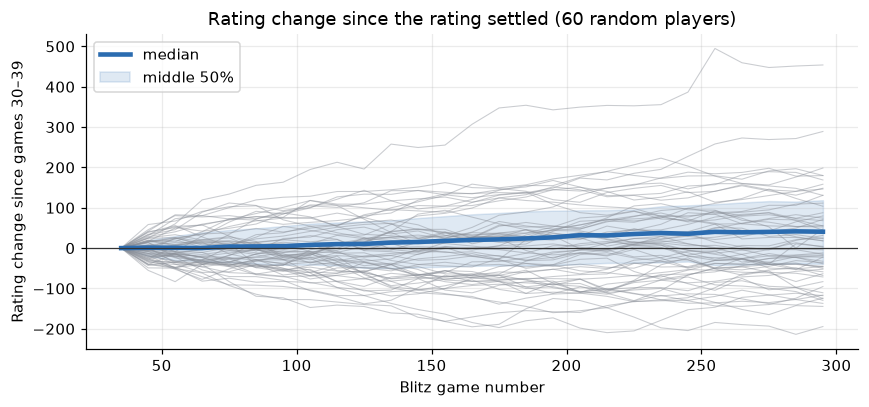

In [2]:
curves = pd.DataFrame({p: curve(g.rating_after.to_numpy()) for p, g in by_player.items()}).T
assert curves.shape[1] == N_POINTS and not curves.isna().any().any()
ax_df = pd.DataFrame([axes(c) for c in curves.to_numpy()], index=curves.index, columns=["gain", "bend"])

fig, ax = plt.subplots(figsize=(8, 3.8))
rng = np.random.default_rng(0)
for p in rng.choice(curves.index, 60, replace=False):
    ax.plot(X_AXIS, curves.loc[p], color=GREY, lw=.7, alpha=.45)
ax.plot(X_AXIS, curves.median(), color=BLUE, lw=3, label="median")
ax.fill_between(X_AXIS, curves.quantile(.25), curves.quantile(.75), color=BLUE, alpha=.15, label="middle 50%")
ax.axhline(0, color="#333", lw=.8)
ax.set(title="Rating change since the rating settled (60 random players)", xlabel="Blitz game number",
       ylabel="Rating change since games 30–39")
ax.legend(loc="upper left")
save("curves-overview")
pd.Series({"Players": len(curves), "Median gain by game 300": round(ax_df.gain.median()),
           "Gained 100+": f"{(ax_df.gain >= 100).mean():.0%}", "Lost 50+": f"{(ax_df.gain <= -50).mean():.0%}"}).to_frame("value")

## Q1. Are there distinct types of learning curve?

Three checks:

- **Principal components** of the 27-point curves: how many independent shapes are there?
- **Gaussian mixtures** on the first three components: does the data prefer several groups (lower BIC) over one?
- **k-means** on two interpretable numbers per curve: **gain** (how much the rating moved by game 300) and **bend** (whether the middle of the curve sits above a straight line, meaning an early rise, or below it, meaning a late rise). For each number of groups, a **bootstrap** refits the clustering on resampled players 50 times and measures how often players land in the same group (adjusted Rand index; 1 = identical).

In [3]:
pca = PCA(5).fit(curves)
var = pd.Series(pca.explained_variance_ratio_, index=[f"PC{i}" for i in range(1, 6)])
Zp = pca.transform(curves)[:, :3]
bic = pd.Series({k: GaussianMixture(k, n_init=5, random_state=0).fit(Zp).bic(Zp) for k in range(1, 7)})

Z = (ax_df / ax_df.std()).to_numpy()
rng = np.random.default_rng(1)
rows = []
for k in range(2, 8):
    km = KMeans(k, n_init=30, random_state=0).fit(Z)
    ari = [adjusted_rand_score(km.labels_, KMeans(k, n_init=10, random_state=b).fit(Z[rng.choice(len(Z), len(Z))]).predict(Z))
           for b in range(50)]
    rows.append({"groups": k, "silhouette": silhouette_score(Z, km.labels_), "bootstrap ARI": np.mean(ari),
                 "smallest group": np.bincount(km.labels_).min()})
q1 = pd.DataFrame(rows).set_index("groups").round(3)
print("Variance explained by each principal component:", var.round(3).to_dict())
print("Gaussian-mixture BIC (lower is better), 1–6 groups:", bic.round(0).to_dict())
display(q1)

Variance explained by each principal component: {'PC1': 0.894, 'PC2': 0.053, 'PC3': 0.02, 'PC4': 0.009, 'PC5': 0.006}
Gaussian-mixture BIC (lower is better), 1–6 groups: {1: 22688.0, 2: 22681.0, 3: 22665.0, 4: 22599.0, 5: 22714.0, 6: 22690.0}


,silhouette,bootstrap ARI,smallest group
groups,,,
2,0.392,0.898,281
3,0.323,0.628,139
4,0.345,0.705,106
5,0.344,0.635,12
6,0.320,0.555,12
7,0.318,0.472,4


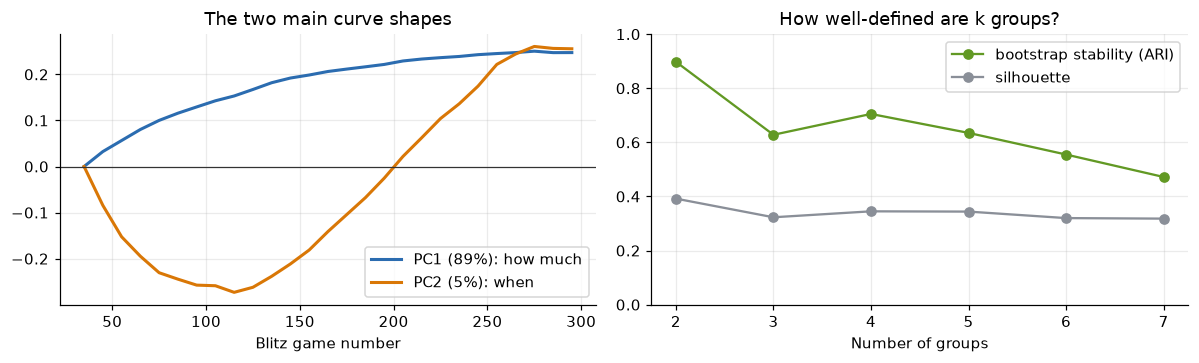

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
comps = pca.components_ * np.sign(pca.components_[:, -1:])
ax[0].plot(X_AXIS, comps[0], color=BLUE, lw=2, label=f"PC1 ({var.iloc[0]:.0%}): how much")
ax[0].plot(X_AXIS, comps[1], color=ORANGE, lw=2, label=f"PC2 ({var.iloc[1]:.0%}): when")
ax[0].axhline(0, color="#333", lw=.8); ax[0].legend(); ax[0].set(title="The two main curve shapes", xlabel="Blitz game number")
ax[1].plot(q1.index, q1["bootstrap ARI"], "o-", color=GREEN, label="bootstrap stability (ARI)")
ax[1].plot(q1.index, q1["silhouette"], "o-", color=GREY, label="silhouette")
ax[1].set(title="How well-defined are k groups?", xlabel="Number of groups", ylim=(0, 1)); ax[1].legend()
save("curves-q1-structure")

**Reading the result.** One shape dominates: PC1, an overall rise or fall that is steepest early (a classic learning curve), explains most of the variation. PC2 is *timing*: early rise versus late rise. The mixture's BIC improves only slightly with more groups, and silhouettes stay low. So learning curves form a **continuum**, not sharply separated types.

Types are still useful as **regions** of that continuum. Two groups are the most stable (high vs low gain), but say little. **Four** groups are the most informative choice that stays reasonably stable, and they separate timing as well as size. They are named from their centres below.

,gain,bend
Fast starter,188.0,65.0
Late climber,123.0,-37.0
Holding steady,26.0,20.0
Declining,-89.0,-51.0


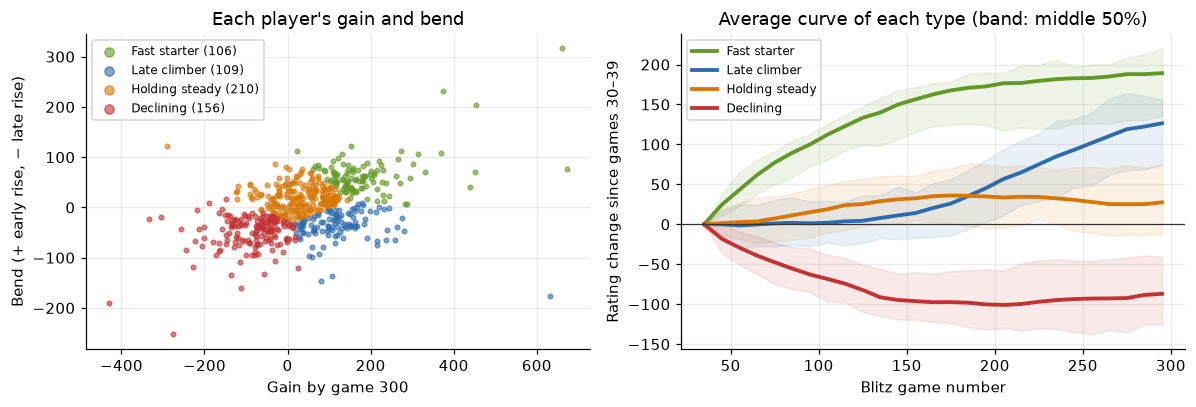

In [5]:
K = 4
km = KMeans(K, n_init=50, random_state=0).fit(Z)
cent = pd.DataFrame(km.cluster_centers_ * ax_df.std().to_numpy(), columns=["gain", "bend"])
order = cent.sort_values("gain").index.tolist()          # lowest gain first
top_two = cent.loc[order[2:]].sort_values("bend").index.tolist()
NAMES = {order[0]: "Declining", order[1]: "Holding steady", top_two[0]: "Late climber", top_two[1]: "Fast starter"}
DESC = {
    "Fast starter": "Big gains soon after the rating settles, then levelling off.",
    "Late climber": "A slow or dipping start, then a steady climb later on.",
    "Holding steady": "Little net change: the rating stays close to where it settled.",
    "Declining": "The rating drifts down after settling, often because the starting rating was too high.",
}
TYPE_ORDER = ["Fast starter", "Late climber", "Holding steady", "Declining"]
TYPE_COL = {"Fast starter": GREEN, "Late climber": BLUE, "Holding steady": ORANGE, "Declining": RED}
ax_df["type"] = [NAMES[l] for l in km.labels_]

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for t in TYPE_ORDER:
    m = ax_df.type == t
    ax[0].scatter(ax_df.gain[m], ax_df.bend[m], s=9, alpha=.6, color=TYPE_COL[t], label=f"{t} ({m.sum()})")
    ax[1].plot(X_AXIS, curves[m].mean(), color=TYPE_COL[t], lw=2.5, label=t)
    ax[1].fill_between(X_AXIS, curves[m].quantile(.25), curves[m].quantile(.75), color=TYPE_COL[t], alpha=.1)
ax[0].set(title="Each player's gain and bend", xlabel="Gain by game 300", ylabel="Bend (+ early rise, − late rise)")
ax[0].legend(fontsize=8, markerscale=2)
ax[1].axhline(0, color="#333", lw=.8)
ax[1].set(title="Average curve of each type (band: middle 50%)", xlabel="Blitz game number", ylabel="Rating change since games 30–39")
ax[1].legend(fontsize=8)
save("curves-types")
cent.rename(index=NAMES).loc[TYPE_ORDER].round(0)

## Q2. How do the types differ?

For each type: how many players, where they started, how fast they played their first 100 games, how much of games 130–300 they spent on a plateau (the window rule from the plateau study), and **what happened next**, from game 300 to 700, for players with 700 games.

In [6]:
w = pd.read_parquet(DATA / "windows.parquet", columns=["player", "end", "flat"])
flat_share = w[w.end <= CURVE_END].groupby("player").flat.mean()
early = pd.DataFrame({p: early_features(g) for p, g in by_player.items()}).T.astype(float)
after = pd.Series({p: g.rating_after.iloc[690:700].mean() - g.rating_after.iloc[290:300].mean()
                   for p, g in by_player.items() if len(g) >= 700})
prof = pd.DataFrame({
    "players": ax_df.type.value_counts(),
    "share": ax_df.type.value_counts(normalize=True).round(2),
    "start rating": early.start_rating.groupby(ax_df.type).median().round(0),
    "gain by 300": ax_df.gain.groupby(ax_df.type).median().round(0),
    "games/week (first 100)": early.games_per_week.groupby(ax_df.type).median().round(0),
    "time on plateau (130–300)": flat_share.groupby(ax_df.type).mean().round(2),
    "change 300→700": after.groupby(ax_df.type).median().round(0),
    "players with 700": after.groupby(ax_df.type).size(),
}).loc[TYPE_ORDER]
display(prof)
kw = stats.kruskal(*[after[ax_df.type.reindex(after.index) == t] for t in TYPE_ORDER])
print(f"Change 300→700 differs between types: Kruskal–Wallis p = {kw.pvalue:.3g}")

,players,share,start rating,gain by 300,games/week (first 100),time on plateau (130–300),change 300→700,players with 700
type,,,,,,,,
Fast starter,106,0.18,1353.0,158.0,50.0,0.24,46.0,79
Late climber,109,0.19,1149.0,114.0,45.0,0.26,46.0,80
Holding steady,210,0.36,1431.0,27.0,50.0,0.42,61.0,182
Declining,156,0.27,1415.0,-74.0,53.0,0.32,51.0,125


Change 300→700 differs between types: Kruskal–Wallis p = 0.549


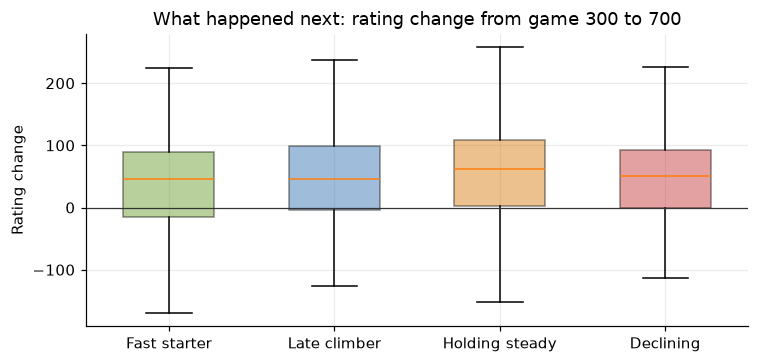

In [7]:
fig, ax = plt.subplots(figsize=(7, 3.4))
data = [after[ax_df.type.reindex(after.index) == t] for t in TYPE_ORDER]
bp = ax.boxplot(data, tick_labels=TYPE_ORDER, showfliers=False, patch_artist=True, widths=.55)
for patch, t in zip(bp["boxes"], TYPE_ORDER):
    patch.set_facecolor(TYPE_COL[t]); patch.set_alpha(.45)
ax.axhline(0, color="#333", lw=.8)
ax.set(title="What happened next: rating change from game 300 to 700", ylabel="Rating change")
save("curves-q2-after")

**Reading the result.**

- **Fast starters** and **late climbers** gain about the same by game 300; they differ in *when*. Late climbers start lower (median 1149 vs 1353), so part of their slow start is the rating finding its level.
- **Holding steady** players spend the most time on plateaus (42% of windows), as expected.
- **Decliners** start highest among the four (median 1415): a provisional rating that overshot and then corrected.
- **What happens next doesn't depend on the type.** From game 300 to 700, all four types gained a similar median of +46 to +61 (Kruskal–Wallis p = 0.55). The early curve describes the start of a career, not a lasting trait.

## Q3. Can the first 100 games predict the type?

Thirteen features from each player's **first 100 games** only: the settled starting rating, how far the provisional games moved the rating, the trend and streakiness over games 30–100, results, opponent strength, pace, breaks, opening variety, game length, losses on time and clock use.

The type depends on the whole curve to game 300, and games 30–100 are the first quarter of it. So the early trend is a strong but partly mechanical predictor. The baselines show how much the other features add. Models are tested with **5-fold cross-validation, repeated 5 times**; each player is in the test set once per repeat.

Measures: **accuracy**, **macro-F1** (the average F1 over the four types, so small types count equally) and **log loss** (quality of the probabilities; lower is better).

In [8]:
y = ax_df.type.loc[early.index]
Xe = early[EARLY_FEATURES].fillna(early[EARLY_FEATURES].median())
CLASSES = TYPE_ORDER

def logloss(y_true, P):
    """Log loss with columns in CLASSES order (sklearn's log_loss would sort the labels alphabetically)."""
    idx = np.array([CLASSES.index(t) for t in y_true])
    return float(-np.mean(np.log(np.clip(P[np.arange(len(idx)), idx], 1e-15, 1))))

SIMPLE = ["start_rating", "early_trend"]
def logit(): return make_pipeline(StandardScaler(), LogisticRegression(C=0.5, max_iter=2000))
MODELS = {
    "Most common type": None,
    "Start rating + early trend (logistic)": (SIMPLE, logit),
    "All features (logistic)": (EARLY_FEATURES, logit),
    "All features (gradient boosting)": (EARLY_FEATURES, lambda: GradientBoostingClassifier(
        n_estimators=150, max_depth=2, learning_rate=0.05, subsample=0.8, random_state=0)),
}
oof = {}
res = []
for name, spec in MODELS.items():
    accs, f1s, lls, probs = [], [], [], np.zeros((len(y), K))
    for rep in range(5):
        P = np.zeros((len(y), K))
        for tr, te in StratifiedKFold(5, shuffle=True, random_state=rep).split(Xe, y):
            if spec is None:
                freq = y.iloc[tr].value_counts(normalize=True).reindex(CLASSES).to_numpy()
                P[te] = freq
            else:
                cols, mk = spec
                m = mk().fit(Xe.iloc[tr][cols], y.iloc[tr])
                P[te] = m.predict_proba(Xe.iloc[te][cols])[:, [list(m.classes_).index(c) for c in CLASSES]]
        pred = np.array(CLASSES)[P.argmax(1)]
        accs.append(accuracy_score(y, pred)); f1s.append(f1_score(y, pred, average="macro")); lls.append(logloss(y, P))
        probs += P / 5
    oof[name] = probs
    res.append({"model": name, "accuracy": np.mean(accs), "macro-F1": np.mean(f1s), "log loss": np.mean(lls)})
q3 = pd.DataFrame(res).set_index("model").round(3)
q3

,accuracy,macro-F1,log loss
model,,,
Most common type,0.361,0.133,1.345
Start rating + early trend (logistic),0.601,0.550,0.919
All features (logistic),0.601,0.556,0.932
All features (gradient boosting),0.583,0.550,1.007


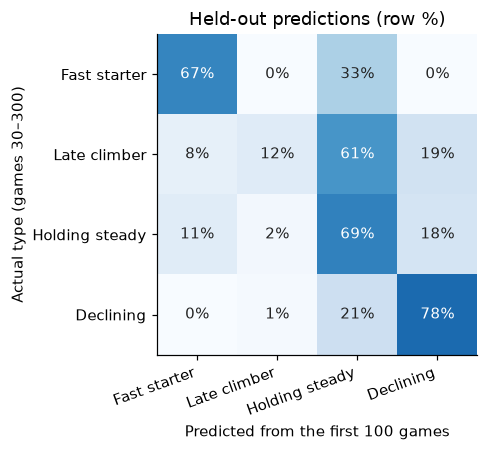

In [9]:
# The two-feature model predicts as well as all thirteen, so it is the one exported to the dashboard.
best = "Start rating + early trend (logistic)"
cm = confusion_matrix(y, np.array(CLASSES)[oof[best].argmax(1)], labels=CLASSES, normalize="true")
fig, ax = plt.subplots(figsize=(5.4, 4.2))
im = ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)
for i in range(K):
    for j in range(K):
        ax.text(j, i, f"{cm[i, j]:.0%}", ha="center", va="center", color="white" if cm[i, j] > .5 else "#222")
ax.set(xticks=range(K), yticks=range(K), xticklabels=CLASSES, yticklabels=CLASSES,
       xlabel="Predicted from the first 100 games", ylabel="Actual type (games 30–300)", title="Held-out predictions (row %)")
ax.grid(False); plt.setp(ax.get_xticklabels(), rotation=20, ha="right")
save("curves-q3-confusion")

**Reading the result.** The first 100 games pick the right type **60% of the time**, against 36% for always guessing the most common type, and the probabilities are well calibrated. But almost all of that comes from the **early trend** and **starting rating**: the other eleven features add nothing measurable, and gradient boosting does no better. Fast starters and decliners are recognised best. Late climbers are the hardest, because by game 100 they look like holders or decliners.

## Q4. Which early signals matter?

The logistic model's coefficients, on standardised features: each cell is the change in log-odds of a type for one standard deviation more of the feature. Red means more likely, blue less likely.

,Fast starter,Late climber,Holding steady,Declining
early_trend,2.28,-0.43,0.02,-1.88
win_rate,1.17,-0.05,-0.05,-1.07
opp_diff,0.67,-0.08,-0.02,-0.57
avg_plies,0.37,-0.24,-0.13,0.00
time_use,-0.02,0.24,0.14,-0.36
provisional_gain,-0.30,-0.13,0.11,0.32
start_rating,-0.30,-0.13,0.11,0.32
early_resid_sd,0.31,-0.16,-0.05,-0.11
games_per_week,0.16,-0.19,0.03,0.00
draw_rate,0.14,0.12,-0.09,-0.17


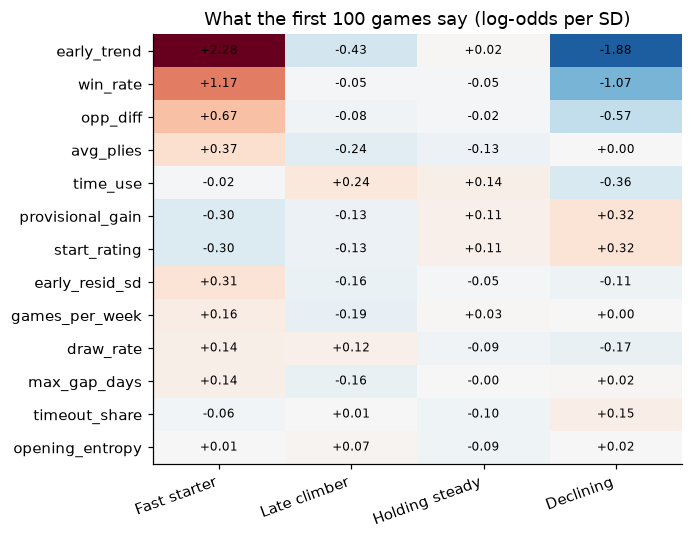

In [10]:
full = logit().fit(Xe, y)
coef = pd.DataFrame(full[-1].coef_, index=full[-1].classes_, columns=EARLY_FEATURES).loc[CLASSES]
show = coef.T.loc[coef.abs().max().sort_values(ascending=False).index]
fig, ax = plt.subplots(figsize=(6.4, 5))
lim = np.abs(show.values).max()
ax.imshow(show.values, cmap="RdBu_r", vmin=-lim, vmax=lim, aspect="auto")
for i in range(show.shape[0]):
    for j in range(show.shape[1]):
        ax.text(j, i, f"{show.values[i, j]:+.2f}", ha="center", va="center", fontsize=8)
ax.set(xticks=range(K), xticklabels=CLASSES, yticks=range(len(show)), yticklabels=show.index,
       title="What the first 100 games say (log-odds per SD)")
ax.grid(False); plt.setp(ax.get_xticklabels(), rotation=20, ha="right")
save("curves-q4-coefficients")
show.round(2)

**Reading the result.** Beyond the trend, a higher **win rate** and **stronger opponents** (players already beating higher-rated players) point to a fast start; using more of the clock points away from decline. The effects are small next to the trend itself, which is why they don't improve the cross-validated scores.

## Q5. Does early engine accuracy add anything?

Stockfish analysed every 4th game of 250 players (see the plateau study). For those players, average accuracy over their first 100 games (about 25 analysed games) is added to the logistic model, and cross-validated on the same subset with and without it.

In [11]:
sf_files = sorted((DATA / "sf").glob("*.parquet"))
sf = pd.concat([pd.read_parquet(f, columns=["player", "idx", "sf_accuracy"]) for f in sf_files], ignore_index=True)
acc = sf[sf.idx < EARLY].groupby("player").sf_accuracy.agg(["mean", "size"]).query("size >= 10")["mean"].rename("early_accuracy")
sub = Xe.join(acc, how="inner")
ys = y.loc[sub.index]
print(f"{len(sub)} players with early engine data; mean early accuracy by type:")
display(acc.groupby(ax_df.type).agg(["mean", "size"]).loc[CLASSES].round(2))
kw_acc = stats.kruskal(*[acc[ax_df.type.reindex(acc.index) == t] for t in CLASSES])
print(f"Early accuracy differs between types: Kruskal–Wallis p = {kw_acc.pvalue:.3g}")
rows = []
for name, cols in [("Without accuracy", EARLY_FEATURES), ("With early accuracy", EARLY_FEATURES + ["early_accuracy"])]:
    f1s, lls = [], []
    for rep in range(10):
        P = np.zeros((len(ys), K))
        for tr, te in StratifiedKFold(5, shuffle=True, random_state=rep).split(sub, ys):
            m = logit().fit(sub.iloc[tr][cols], ys.iloc[tr])
            P[te] = m.predict_proba(sub.iloc[te][cols])[:, [list(m.classes_).index(c) for c in CLASSES]]
        f1s.append(f1_score(ys, np.array(CLASSES)[P.argmax(1)], average="macro")); lls.append(logloss(ys, P))
    rows.append({"model": name, "macro-F1": np.mean(f1s), "log loss": np.mean(lls)})
q5 = pd.DataFrame(rows).set_index("model").round(3)
q5

250 players with early engine data; mean early accuracy by type:


,mean,size
type,,
Fast starter,86.75,51
Late climber,84.65,43
Holding steady,85.89,91
Declining,84.94,65


Early accuracy differs between types: Kruskal–Wallis p = 0.000258


,macro-F1,log loss
model,,
Without accuracy,0.544,0.914
With early accuracy,0.540,0.925


**Reading the result.** Fast starters played more accurately from the start (86.8% vs 84.7% for late climbers, p < 0.001), so accuracy does track the type. But it adds nothing to the prediction once the early trend is known: a player who plays accurately is already gaining rating.

## Robustness: a longer horizon

The same method on games 30–700, for the 478 players who reached 700 games. If the 300-game types are meaningful, they should line up with the 700-game ones.

In [12]:
long = {p: curve(g.rating_after.to_numpy(), end=700) for p, g in by_player.items() if len(g) >= 700}
ax_l = pd.DataFrame([axes(c) for c in long.values()], index=list(long), columns=["gain", "bend"])
Zl = (ax_l / ax_l.std()).to_numpy()
kml = KMeans(K, n_init=50, random_state=0).fit(Zl)
cl = pd.DataFrame(kml.cluster_centers_ * ax_l.std().to_numpy(), columns=["gain", "bend"])
o = cl.sort_values("gain").index.tolist(); t2 = cl.loc[o[2:]].sort_values("bend").index.tolist()
NL = {o[0]: "Declining", o[1]: "Holding steady", t2[0]: "Late climber", t2[1]: "Fast starter"}
ax_l["type"] = [NL[l] for l in kml.labels_]
both = ax_df.type.loc[ax_l.index]
print(f"Agreement between 300-game and 700-game types: ARI = {adjusted_rand_score(both, ax_l.type):.2f}, "
      f"same name for {np.mean(both == ax_l.type):.0%} of players")
pd.crosstab(both.rename("type at 300"), ax_l.type.rename("type at 700")).loc[CLASSES, CLASSES]

Agreement between 300-game and 700-game types: ARI = 0.26, same name for 53% of players


type at 700,Fast starter,Late climber,Holding steady,Declining
type at 300,,,,
Fast starter,60,9,10,0
Late climber,34,25,21,0
Holding steady,10,77,71,24
Declining,0,16,18,91


**Reading the result.** The two horizons only partly agree (adjusted Rand index about 0.26). Decliners and fast starters mostly keep their label; many 300-game late climbers become fast starters on the longer view, and many holders become late climbers. That fits the continuum picture: the type is a description of a stretch of games, not a fixed category.

## Summary

- Learning curves are **one continuum**: mostly *how much* the rating moves, plus a smaller *when*. Four types (fast starter, late climber, holding steady, declining) are useful labels for regions of it, with moderate stability.
- The **first 100 games predict the type 60% of the time** (36% by chance), almost entirely through the early trend and starting rating.
- The type **doesn't predict what happens after game 300**: all types gain about +50 from game 300 to 700.

## Export for the NeuralGambit dashboard

`curves.json` holds everything the browser needs: the curve settings, the four type centres (for players with 300+ games), each type's average curve and middle 50% (for the chart), and the two-feature logistic model with its scaler (for players with 100–299 games). A check confirms that the exported formulas reproduce scikit-learn.

In [13]:
final = logit().fit(Xe[SIMPLE], y)
lr = final[-1]
sd = ax_df[["gain", "bend"]].std()
types = []
for t in CLASSES:
    m = ax_df.type == t
    label = [k for k, v in NAMES.items() if v == t][0]
    types.append({"name": t, "desc": DESC[t], "n": int(m.sum()), "share": round(float(m.mean()), 3),
                  "centre": [round(float(v), 4) for v in km.cluster_centers_[label]],
                  "curve": [round(float(v), 1) for v in curves[m].mean()],
                  "q25": [round(float(v), 1) for v in curves[m].quantile(.25)],
                  "q75": [round(float(v), 1) for v in curves[m].quantile(.75)],
                  "after_300_700": None if pd.isna(prof.loc[t, "change 300→700"]) else float(prof.loc[t, "change 300→700"])})
scaler = final[0]
spec = {
    "skip": SKIP, "curve_end": CURVE_END, "block": BLOCK, "early": EARLY,
    "axis_sd": [round(float(sd.gain), 4), round(float(sd.bend), 4)],
    "types": types,
    "model": {"features": SIMPLE, "classes": list(lr.classes_),
              "mean": [round(float(v), 6) for v in scaler.mean_], "scale": [round(float(v), 6) for v in scaler.scale_],
              "coef": [[round(float(v), 6) for v in row] for row in lr.coef_], "intercept": [round(float(v), 6) for v in lr.intercept_],
              },
    "meta": {"n_players": len(curves), "cv_accuracy": float(q3.loc[best, "accuracy"]), "cv_macro_f1": float(q3.loc[best, "macro-F1"]),
             "baseline_accuracy": float(q3.loc["Most common type", "accuracy"])},
}
(OUT / "curves.json").write_text(json.dumps(spec, indent=1))

# check: the exported numbers reproduce scikit-learn
def predict_exported(s, X):
    z = (X[s["model"]["features"]].to_numpy() - s["model"]["mean"]) / s["model"]["scale"]
    logits = z @ np.array(s["model"]["coef"]).T + s["model"]["intercept"]
    e = np.exp(logits - logits.max(1, keepdims=True)); return e / e.sum(1, keepdims=True)
def assign_exported(s, gain, bend):
    z = np.array([gain / s["axis_sd"][0], bend / s["axis_sd"][1]])
    return s["types"][int(np.argmin([np.sum((z - np.array(t["centre"])) ** 2) for t in s["types"]]))]["name"]
diff = np.abs(predict_exported(spec, Xe) - final.predict_proba(Xe[SIMPLE])).max()
same = np.mean([assign_exported(spec, r.gain, r.bend) == r.type for r in ax_df.itertuples()])
print(f"max probability difference: {diff:.1e}; type assignment matches for {same:.0%} of players")
APP_STATIC = ROOT.parents[1] / "static" / "plateau"
shutil.copy(OUT / "curves.json", APP_STATIC / "curves.json")
print("wrote", OUT / "curves.json", f"({(OUT / 'curves.json').stat().st_size / 1024:.0f} KB), copied to", APP_STATIC)

max probability difference: 2.7e-07; type assignment matches for 100% of players
wrote C:\Users\marko\PycharmProjects\Chessmatics\research\plateau\out\curves.json (6 KB), copied to C:\Users\marko\PycharmProjects\Chessmatics\static\plateau
